### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree

### Decision Tree Regressor

In [3]:
# Linear data: y = 3x + 5 + noise
rng = np.random.RandomState(42)
X = np.linspace(0, 10, 100).reshape(-1, 1)
y = 3 * X[:, 0] + 5 + rng.normal(scale=2.0, size=X.shape[0])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
# Models
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [5]:
# Predictions on a smooth grid
X_plot = np.linspace(0, 10, 300).reshape(-1, 1)
y_lin = lin_reg.predict(X_plot)
y_tree = tree.predict(X_plot)

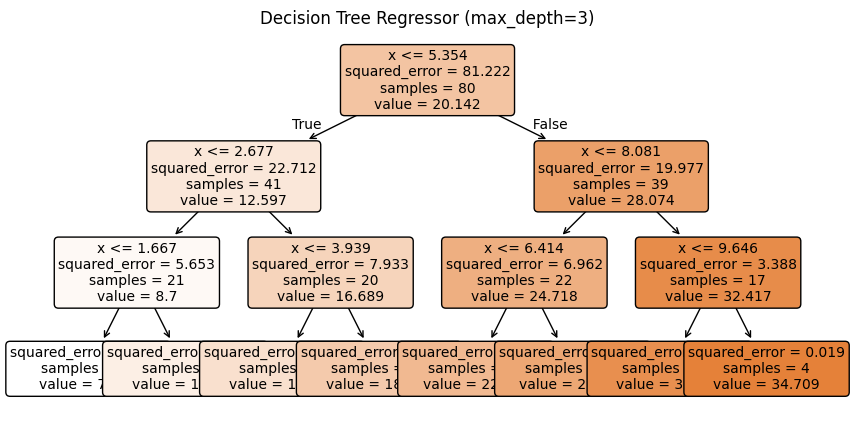

In [6]:
plt.figure(figsize=(10, 5))
plot_tree(
    tree,
    feature_names=["x"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Regressor (max_depth=3)")
plt.show()

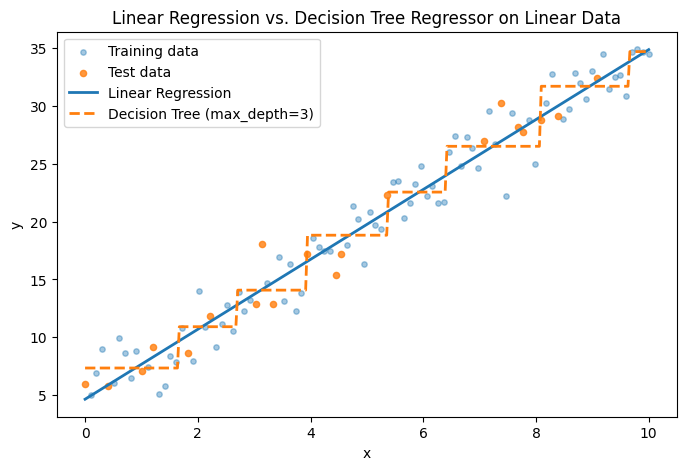

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.4, s=15, label="Training data")
plt.scatter(X_test, y_test, alpha=0.8, s=20, label="Test data")
plt.plot(X_plot, y_lin, linewidth=2, label="Linear Regression")
plt.plot(X_plot, y_tree, linewidth=2, linestyle="--", label="Decision Tree (max_depth=3)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression vs. Decision Tree Regressor on Linear Data")
plt.legend()
plt.show()

გადაწყვეტილების ხის მინუსები წრფივ რეგრესიაში:

* Fitting Line - Piecewise-constant predictions (step function)
    - → ხე ქმნის მხოლოდ ნაბიჯ-ნაბიჯ მუდმივ მნიშვნელობებს, ხოლო რეალური ფუნქცია შეიძლება იყოს სწორი ხაზი. Linear Regression უკეთესად აჩვენებს ასეთ დამოკიდებულებას.

* High variance (overfitting)
    - → პატარა ცვლილებაც კი მონაცემებში ხის მთლიან სტრუქტურას ცვლის. Linear Regression ბევრად უფრო სტაბილურია.

* Poor extrapolation outside training range
    - → ცუდად ექსტრაპოლირებს, საზღვრებს გარეთ ბოლო ფოთლის საშუალოს აბრუნებს. Linear Regression წრფივ ხაზს აგრძელებს.

* Discontinuous prediction curve
    - → ერთი მცირე ცვლილება x-ში იწვევს მკვეთრ ნახტომს y-ში.

* Requires more tuning
    - → საჭიროა პარამეტრების კარგად გამართვა.
      
* Higher risk of underfitting OR overfitting
    - Shallow tree → too few splits → underfits
    - Deep tree → staircase with many blocks → overfits

### Random Forests

Random Forest არის ensemble learning მეთოდი, რომელიც იყენებს ბევრ გადაწყვეტილების ხეს (Decision Tree) პროგნოზირებისთვის.  
უკეთესია, ვიდრე ერთი ხე, რადგან ამცირებს Overfitting-ს და აუმჯობესებს სიზუსტეს.
თითოეული ხე გვაძლევს საკუთარ პროგნოზს და საბოლოო პასუხს განსაზღვრავს უმრავლესობის აზრი ან საშუალო მნიშვნელობა.

---

### საფუძველი: გადაწყვეტილების ხე (Decision Tree)

გადაწყვეტილების ხე ირჩევს მნიშვნელობებს მახასიათებლების მიხედვით და აყალიბებს გადაწყვეტილებებს. მაგ:

```
Node: ასაკი < 30?
   ├─ კი → ხელფასი მაღალია?
   │     ├─ კი → კრედიტი დამტკიცებულია
   │     └─ არა → კრედიტი უარყოფილია
   └─ არა → კრედიტი დამტკიცებულია
```

ერთი ხე შეიძლება იყოს ძალიან ღრმა და მოხდეს Overfitting.

---

#### როგორ მუშაობს Random Forest?
- Bootstrap Sampling → მონაცემთა შემთხვევითი ნაწილების შერჩევა (Bagging).  
- Decision Trees Training → თითოეული ხე სწავლობს სხვადასხვა მონაცემებზე.  
- Majority Voting (კლასიფიკაციისთვის) ან საშუალო აღება (რეგრესიისთვის) → საბოლოო პროგნოზისთვის.  

Random Forest იყენებს ორ მთავარ ტექნიკას Overfitting-ის თავიდან ასაცილებლად:

a) Bagging (Bootstrap Aggregation)

- მოდელი იყენებს ბევრ გადაწყვეტილების ხეს
- თითოეული ხე იღებს შემთხვევით, მონაცემთა შემთხვევით შერჩეულ ნაწილს (Bootstrap Sample) 
- თითოეული ხე სწავლობს და აბრუნებს საკუთარ პროგნოზს
- კლასიფიკაციაში: აირჩევა უმრავლესობის გადაწყვეტილება
- რეგრესიაში: ითვლება საშუალო

b) შემთხვევითი მახასიათებლების შერჩევა გაყოფისას

- ხეს არ აქვს წვდომა ყველა მახასიათებელზე, მხოლოდ შემთხვევით არჩეულ ნაწილზე  
- ეს ამცირებს ხეების ერთმანეთთან კორელაციას და აუმჯობესებს საერთო შედეგს
  
---

#### როდის გამოვიყენოთ Random Forest?
- როცა გვინდა უფრო ზუსტი და სტაბილური პროგნოზი  
- როცა გვაქვს ბევრი მახასიათებელი (Feature) და გვინდა ყველაზე მნიშვნელოვანი გამოვარჩიოთ
- როცა არ გვინდა მონაცემთა წინასწარი დამუშავება

---

## მთავარი პარამეტრები

| პარამეტრი                  | ახსნა                                                             |
|---------------------------|--------------------------------------------------------------------|
| `n_estimators`            | ტყეში არსებული ხეების რაოდენობა                                     |
| `max_depth`               | ხის მაქსიმალური სიღრმე                                             |
| `max_features`            | გაყოფისას გამოყენებული მახასიათებლების შემთხვევითი რაოდენობა      |
| `bootstrap`               | Bootstrap-ის გამოყენება ხდება თუ არა                               |
| `criterion`               | გაყოფის კრიტერიუმი: Gini, Entropy (კლასიფიკაციისთვის)           |

---

#### როგორ მუშაობს Random Forest? Bootstrap Sampling და Bagging  

Random Forest-ის ერთ-ერთი მთავარი ტექნიკა არის Bootstrap Sampling და Bagging.  
ეს მეთოდები უზრუნველყოფს, რომ Decision Trees არ გახდნენ Overfitting-ის მსხვერპლი.  

---

#### Bootstrap Sampling 
Bootstrap Sampling არის მონაცემთა ნაწილების შემთხვევითი შერჩევა ჩანაცვლებით (Sampling with Replacement).  
- ვთვლით N ჩანაწერს მონაცემთა ნაკრებში.  
- შემთხვევითად ვირჩევთ N ჩანაწერს, ზოგიერთი შეიძლება განმეორდეს, ზოგიერთი შეიძლება გამოიტოვოს.  

In [8]:
# მონაცემთა ნაკრების შექმნა (10 ჩანაწერი)
data = np.array(["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"])
df = pd.DataFrame(data, columns=["Samples"])

# Bootstrap Sampling (10 შემთხვევითი შერჩევა ჩანაცვლებით)
bootstrap_sample = np.random.choice(data, size=10, replace=True)
print("Bootstrap Sample:", bootstrap_sample)

# Bootstrap Sampling ამცირებს Overfitting-ის რისკს, 
# რადგან Decision Trees სხვადასხვა მონაცემებზე ისწავლიან

Bootstrap Sample: ['C' 'J' 'G' 'E' 'D' 'H' 'C' 'H' 'B' 'H']


#### Bagging (Bootstrap Aggregating)
Bagging ნიშნავს მრავალი Decision Tree-ს გაწვრთნას პარალელურად და მათი პროგნოზების გაერთიანებას.

- Random Forest ქმნის მრავალ Decision Tree-ს  
- თითოეული Decision Tree სწავლობს Bootstrap Sample-ზე (შემთხვევითად შერჩეულ N ჩანაწერზე)
- პროგნოზი (Prediction):  
  - კლასიფიკაციისას → უმრავლესობის კენჭისყრა (*Majority Voting*)
  - რეგრესიისას → საშუალოს გამოთვლა (*Averaging*)

In [9]:
# 🌳 Random Forest (100 Decision Trees, Bagging + Bootstrap)
rf_model = RandomForestClassifier(n_estimators=100, bootstrap=True, random_state=42) # bootstrap=True (Default)

# თუ bootstrap=False, Bootstrap Sampling გამორთულია (ყველა Decision Tree სწავლობს მთელ მონაცემთა ნაკრებზე, ანუ Bagging არ გამოიყენება).

Bootstrap Sampling უზრუნველყოფს, რომ თითოეული Decision Tree სწავლობს განსხვავებულ მონაცემებზე.

Bagging აერთიანებს Decision Trees-ის შედეგებს, რაც ზრდის სიზუსტეს.

### Random Forest Classifier

##### **Titanic Dataset**: პროგნოზირება, გადარჩება თუ არა მგზავრი Titanic-ის კატასტროფის დროს.

In [10]:
# Titanic Dataset-ის ჩატვირთვა (Open Source)
url_titanic = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
df_titanic = pd.read_csv(url_titanic)
df_titanic.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [11]:
# არასაჭირო სვეტების წაშლა
df_titanic = df_titanic.drop(columns=["Name", "Pclass"])

In [14]:
# მონაცემთა დამუშავება
label_encoder = LabelEncoder()
df_titanic["Sex"] = label_encoder.fit_transform(df_titanic["Sex"])

In [15]:
# ცვლადების გამოყოფა (Features & Target)
X = df_titanic.drop(["Survived"], axis=1)  # Features (დამოუკიდებელი ცვლადები)
y = df_titanic["Survived"]  # Target (დამოკიდებული ცვლადი)

# მონაცემთა გაყოფა (Train-Test Split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
# Random Forest კლასიფიკატორის გაწვრთნა
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [17]:
# პროგნოზი
y_pred = model.predict(X_test)

In [18]:
# შეფასება
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.80


In [19]:
# Classification Report
class_report = classification_report(y_test, y_pred)

print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.84       111
           1       0.75      0.70      0.72        67

    accuracy                           0.80       178
   macro avg       0.79      0.78      0.78       178
weighted avg       0.80      0.80      0.80       178



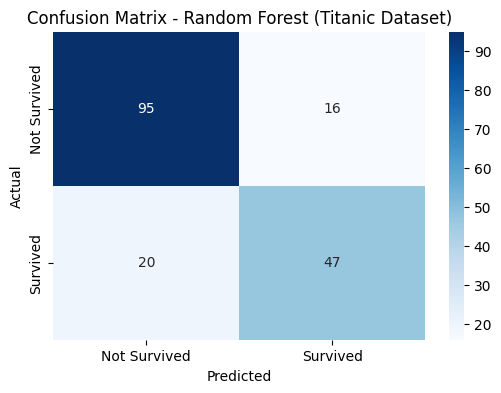

In [20]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Survived", "Survived"], yticklabels=["Not Survived", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest (Titanic Dataset)")
plt.show()

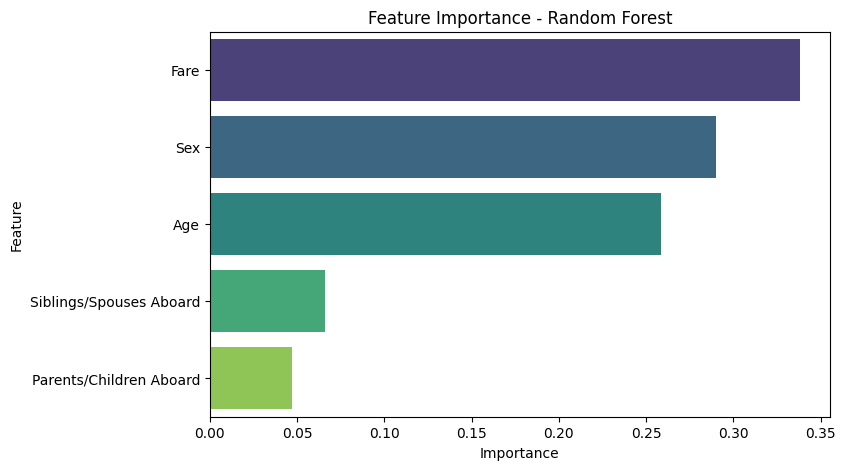

In [21]:
# Feature Importance
importance_df = pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

# შედეგების ვიზუალიზაცია
plt.figure(figsize=(8, 5))
sns.barplot(x=importance_df["Importance"], y=importance_df["Feature"], palette="viridis")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Random Forest");

### Random Forest Regressor

##### California Housing Dataset - სახლის ფასის პროგნოზი

In [22]:
# # მონაცემების ჩატვირთვა
data = fetch_california_housing()
X, y = data.data, data.target * 100000
feature_names = data.feature_names

df_housing = pd.DataFrame(X, columns=feature_names)
df_housing["MedHouseVal"] = y 
df_housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,452600.0
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,358500.0
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,352100.0
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,341300.0
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,342200.0


In [23]:
# Features / Target 
X = df_housing.drop(columns="MedHouseVal")
y = df_housing["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
# Decision Tree Regressor მოდელი გავწვრთვნათ
dtr = DecisionTreeRegressor(max_depth=2, random_state=0)
dtr.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


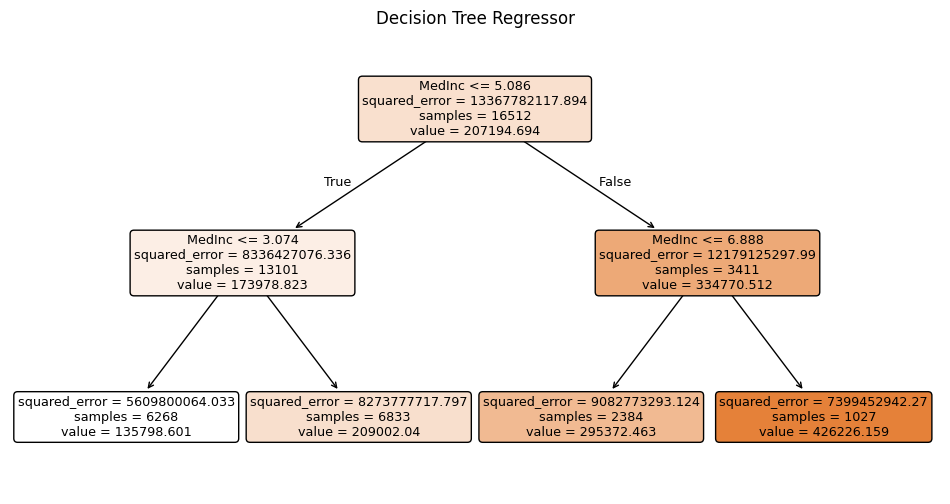

In [25]:
plt.figure(figsize=(12,6))
plot_tree(dtr, feature_names=dtr.feature_names_in_, filled=True, rounded=True)
plt.title("Decision Tree Regressor")
plt.show()

In [26]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
# Predict
y_pred = rf.predict(X_test)

In [28]:
# Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 32659.85
Mean Squared Error (MSE): 2541097170.13
Root Mean Squared Error (RMSE): 50409.30
R² Score: 0.81


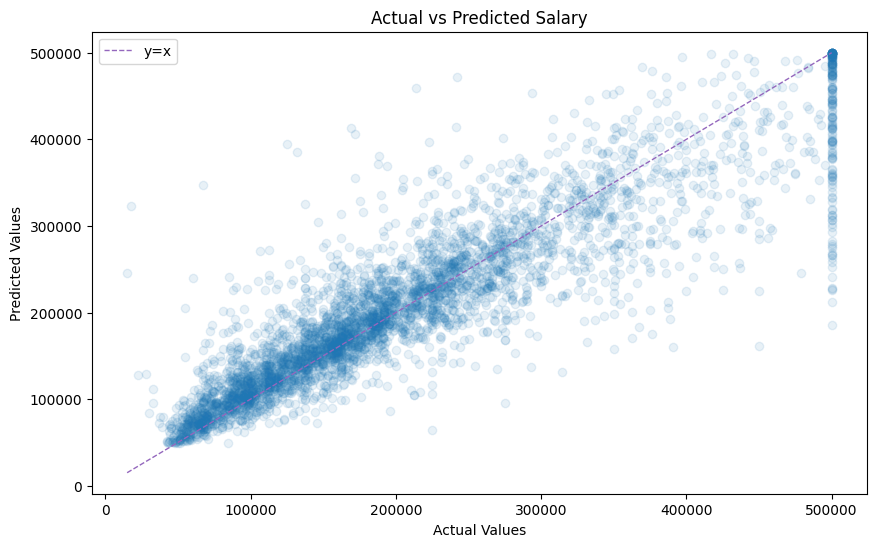

In [29]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.1)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C4", label="y=x")
ax.set_title("Actual vs Predicted Salary")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values")
ax.legend();

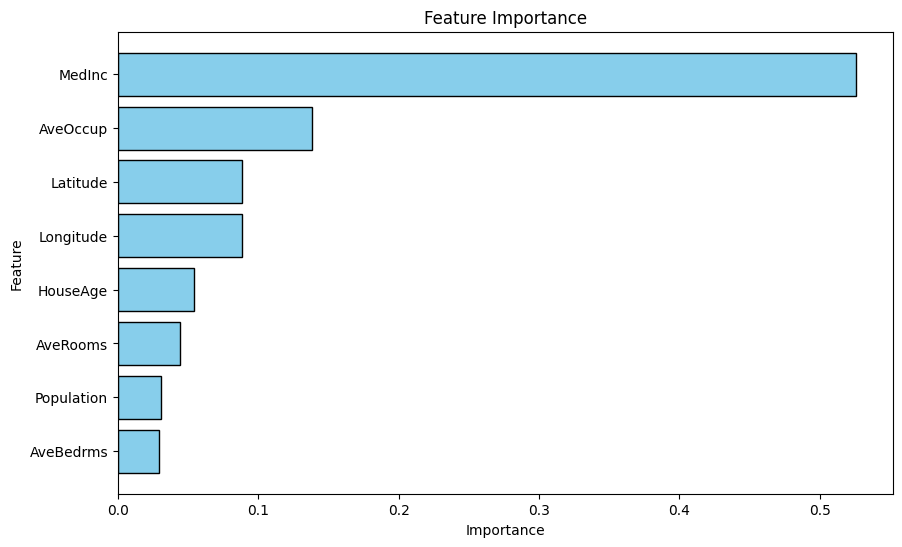

In [30]:
# Feature importance
importance_df = pd.DataFrame({"Feature": rf.feature_names_in_, "Importance": rf.feature_importances_})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue", edgecolor="black")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.gca().invert_yaxis() 
plt.show()

### Cross-validation, Train-Test Split და Holdout მეთოდი

როცა ალგორითმს ვასწავლით, მნიშვნელოვანია მისი სწორი შეფასება, რათა დავრწმუნდეთ, რომ ის კარგად გენერალიზდება ახალ მონაცემებზე.  
მიზანი: თავიდან ავიცილოთ Overfitting (მოდელი ძალიან ზუსტად სწავლობს ტრენინგ მონაცემებს, მაგრამ ვერ ასრულებს კარგად ტესტზე).  

---

#### Penguins Dataset

In [32]:
# მონაცემების ჩატვირთვა
df_penguins = sns.load_dataset("penguins")
df_penguins = df_penguins.dropna().reset_index(drop=True)[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "species"]]
df_penguins.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
3,36.7,19.3,193.0,3450.0,Adelie
4,39.3,20.6,190.0,3650.0,Adelie


In [33]:
# მახასიათებლების და სამიზნე ცვლადის გამოყოფა
X, y = df_penguins.drop(columns="species"), df_penguins["species"]

#### Train-Test Split  
- ყველაზე მარტივი მეთოდი  
- მონაცემთა ნაწილებად გაყოფა:  
  - სასწავლო (Train Set) → მოდელის გასაწვრთნელად  
  - ტესტირების (Test Set) → მოდელის შესამოწმებლად  

In [34]:
# მონაცემების გაყოფა (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train data: {X_train.shape}, {y_train.shape}")
print(f"Test data: {X_test.shape}, {y_test.shape}")

Train data: (266, 4), (266,)
Test data: (67, 4), (67,)


<img src="../../images/train_test.png" alt="train_test" width=800>

#### Holdout Method  
✔ გაუმჯობესებული Train-Test Split მეთოდი  
✔ მონაცემთა სამ ნაწილად გაყოფა:  
  - სასწავლო (Train Set)
  - Validation Set → ჰიპერპარამეტრების ოპტიმიზაციისთვის  
  - სატესტო (Test Set) → მოდელის საბოლოო შეფასებისთვის  

In [35]:
# მონაცემთა გაყოფა (60% Train, 20% Validation, 20% Test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Train data: {X_train.shape}, {y_train.shape}")
print(f"Validation data: {X_val.shape}, {y_val.shape}")
print(f"Test data: {X_test.shape}, {y_test.shape}")

Train data: (199, 4), (199,)
Validation data: (67, 4), (67,)
Test data: (67, 4), (67,)


####  Cross-Validation (CV)
- ყველაზე სტაბილური მეთოდი  
- მონაცემთა მრავალჯერადი ტრენინგი და ტესტირება  
- კარგი შედეგი მცირე მონაცემებთანაც!  

როგორ მუშაობს? (K-Fold Cross-Validation)  
1. მონაცემთა K ნაწილად გაყოფა (მაგ. 5-fold CV → 5 ნაწილად).  
2. K-ჯერ ვაწვდით მოდელს (ყოველ ჯერზე ვცვლით სატესტო ნაწილს).  
3. ვიღებთ საშუალო სიზუსტეს, რომელიც უკეთეს შეფასებას იძლევა. 

<img src="../../images/kfolds.png" alt="kfold" width=1000>

In [44]:
# DecisionTreeClassifier კლასიფიკატორი
model = DecisionTreeClassifier(random_state=42)

# Cross-Validation შეფასება (5-fold CV)
scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")

print(f"Cross-Validation results: {scores}")
print(f"Mean accuracy: {scores.mean():.2f}")

Cross-Validation results: [0.6375     0.625      0.696875   0.7        0.54545455]
Mean accuracy: 0.64


#### განსხვავება
| მეთოდი | შეფასება |
|------------|------------------|
| Train-Test Split | მარტივი და სწრაფი, თუმცა შესაძლებელია მონაცემების არათანაბარი განაწილება |
| Holdout Method | უკეთესი ჰიპერპარამეტრების ოპტიმიზაცია |
| Cross-Validation | ყველაზე სტაბილური შეფასება, თუმცა უფრო ნელია, ვიდრე სხვები |

თუ დიდი მონაცემები გაქვს, Train-Test Split საკმარისია.  
თუ ჰიპერპარამეტრების ოპტიმიზაცია გჭირდება, Holdout Method.  
თუ ზუსტი შეფასება გჭირდება, Cross-Validation საუკეთესოა!  

In [37]:
X = np.array(["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"]) # feature data 
y = np.array([1, 0, 1, 0, 1, 0, 1, 0, 1, 0]) # labels

# შევქმნათ 5-fold cross-validator
kf = KFold(n_splits=5, shuffle=False)

# დავბეჭდოთ შესაბამისი დაყოფები
for fold, (train_index, test_index) in enumerate(kf.split(X)):
    print(f"Fold {fold + 1}")
    print(f"Train indices: {train_index}")
    print(f"Train X: {X[train_index]}, Train y: {y[train_index]}")
    print(f"Test indices: {test_index}")
    print(f"Test X: {X[test_index]}, Test y: {y[test_index]}")
    print("-" * 50)

Fold 1
Train indices: [2 3 4 5 6 7 8 9]
Train X: ['C' 'D' 'E' 'F' 'G' 'H' 'I' 'J'], Train y: [1 0 1 0 1 0 1 0]
Test indices: [0 1]
Test X: ['A' 'B'], Test y: [1 0]
--------------------------------------------------
Fold 2
Train indices: [0 1 4 5 6 7 8 9]
Train X: ['A' 'B' 'E' 'F' 'G' 'H' 'I' 'J'], Train y: [1 0 1 0 1 0 1 0]
Test indices: [2 3]
Test X: ['C' 'D'], Test y: [1 0]
--------------------------------------------------
Fold 3
Train indices: [0 1 2 3 6 7 8 9]
Train X: ['A' 'B' 'C' 'D' 'G' 'H' 'I' 'J'], Train y: [1 0 1 0 1 0 1 0]
Test indices: [4 5]
Test X: ['E' 'F'], Test y: [1 0]
--------------------------------------------------
Fold 4
Train indices: [0 1 2 3 4 5 8 9]
Train X: ['A' 'B' 'C' 'D' 'E' 'F' 'I' 'J'], Train y: [1 0 1 0 1 0 1 0]
Test indices: [6 7]
Test X: ['G' 'H'], Test y: [1 0]
--------------------------------------------------
Fold 5
Train indices: [0 1 2 3 4 5 6 7]
Train X: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H'], Train y: [1 0 1 0 1 0 1 0]
Test indices: [8 9]
Test X: [

#### Wine data

In [38]:
# Load wine data
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df_wine = pd.read_csv(url, sep=";")
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [39]:
df_wine["quality"].value_counts().sort_index().reset_index()

,quality,count
0,3,10
1,4,53
2,5,681
3,6,638
4,7,199
5,8,18


|Quality | Class|
|--------|-------|
|3–5 | 0 (bad wine)|
|6–8 | 1 (good wine)|

In [40]:
# გარდავქმნათ სამიზნე ცვლადი, განვიხილოთ მხოლოდ 2 კლასი
df_wine["quality"] = (df_wine["quality"] >= 6).astype(int)

In [41]:
# მახასიათებლების (X) და სამიზნის (y) გამოყოფა
X = df_wine.drop("quality", axis=1)
y = df_wine["quality"]

In [42]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

fold = 1
for train_index, test_index in cv.split(X, y):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)   # fit only on train
    X_test_scaled = scaler.transform(X_test)         # transform test

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    print(f"Fold {fold} Accuracy: {acc:.3f}")
    fold += 1

NameError: name 'StandardScaler' is not defined